# 正規－正規モデルにおける縮小推定の導出

## 設定

- 尤度：$\bar{y}_i \sim \mathcal{N}\!\left(\beta_i,\ \dfrac{\sigma^2}{n_i}\right)$（$n_i$ 件の観測平均）
- 事前分布：$\beta_i \sim \mathcal{N}(\mu_\beta, \tau^2)$

## 導出

ベイズの定理より事後分布は：

$$
p(\beta_i \mid \bar{y}_i)
\propto
\underbrace{\exp\!\left(-\frac{n_i(\bar{y}_i - \beta_i)^2}{2\sigma^2}\right)}_{\text{尤度}}
\cdot
\underbrace{\exp\!\left(-\frac{(\beta_i - \mu_\beta)^2}{2\tau^2}\right)}_{\text{事前分布}}
$$

指数部を $\beta_i$ の二次式として整理します。$\beta_i$ に関係する部分は、

$$
-\frac{1}{2}\left[\left(\frac{n_i}{\sigma^2}+\frac{1}{\tau^2}\right)\beta_i^2-2\left(\frac{n_i\bar{y}_i}{\sigma^2}+\frac{\mu_\beta}{\tau^2}\right)\beta_i\right]
$$

となります。ここで、

$$
A=\frac{n_i}{\sigma^2}+\frac{1}{\tau^2},\qquad B=\frac{n_i\bar{y}_i}{\sigma^2}+\frac{\mu_\beta}{\tau^2}
$$

と置いて平方完成すると、

$$
A\beta_i^2-2B\beta_i=A\left(\beta_i-\frac{B}{A}\right)^2-\frac{B^2}{A}
$$

$B^2/A$ は $\beta_i$ に関係しないため、事後分布は平均 $B/A$、分散 $1/A$ の正規分布だと分かります。

**精度**（分散の逆数）に注目すると：

| | 精度 |
|---|---|
| 尤度（データ） | $n_i / \sigma^2$ |
| 事前分布 | $1 / \tau^2$ |
| 事後分布（合計） | $n_i/\sigma^2 + 1/\tau^2$ |

事後平均は**精度を重みとした加重平均**になり：

$$
\hat{\beta}_i^{\text{Bayes}}
= \frac{n_i/\sigma^2}{n_i/\sigma^2 + 1/\tau^2}\cdot\bar{y}_i
+ \frac{1/\tau^2}{n_i/\sigma^2 + 1/\tau^2}\cdot\mu_\beta
\qquad (6.6)
$$

## 直感

精度は「どちらの情報をどれだけ信頼するか」を表します。

- $n_i \to \infty$（データ大量）のとき $w_i \to 1$：$\hat{\beta}_i^{\text{Bayes}} \to \bar{y}_i$（自分のデータを信頼）
- $n_i \to 0$（データほぼなし）のとき $w_i \to 0$：$\hat{\beta}_i^{\text{Bayes}} \to \mu_\beta$（全体平均に引き戻される）

縮小の程度はデータ量 $n_i$ によって自動的に決まります。これが縮小推定の数学的実体です。


## 数値シミュレーションによる確認

式 (6.6) を数値的に検証する。

- $\sigma^2 = 1$（観測分散、既知）
- $\tau^2 = 1$（事前分布の分散）
- $\mu_\beta = 0$（事前平均）
- $n_i$ を変化させて重み $w_i$ と縮小推定量を確認する。


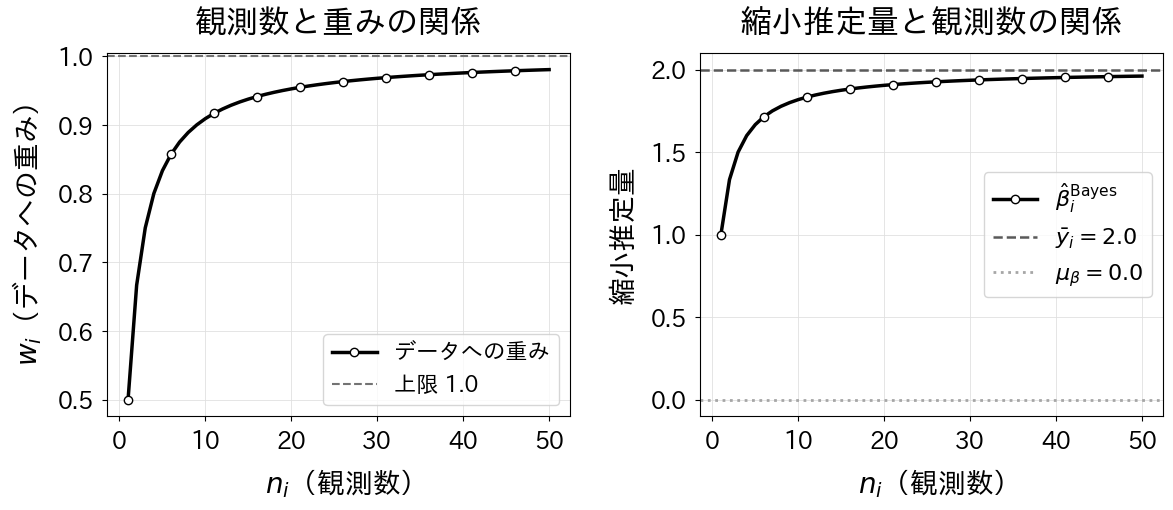

n=1:  w=0.500, beta_bayes=1.000
n=5:  w=0.833, beta_bayes=1.667
n=20: w=0.952, beta_bayes=1.905
n=50: w=0.980, beta_bayes=1.961


In [1]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401
import numpy as np

sigma2 = 1.0  # 観測分散（既知）
tau2 = 1.0  # 事前分布の分散
mu_beta = 0.0  # 事前平均
y_bar = 2.0  # 観測平均（例：真値より高い値）

n_values = np.arange(1, 51)

# 重み w_i = (n_i/sigma^2) / (n_i/sigma^2 + 1/tau^2)
w = (n_values / sigma2) / (n_values / sigma2 + 1 / tau2)

# 縮小推定量
beta_bayes = w * y_bar + (1 - w) * mu_beta

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

axes[0].plot(
    n_values,
    w,
    color="0.0",
    linewidth=2.5,
    linestyle="-",
    marker="o",
    markevery=5,
    markersize=6,
    markerfacecolor="white",
    label="データへの重み",
)
axes[0].set_xlabel("$n_i$（観測数）", fontsize=20, labelpad=10)
axes[0].set_ylabel("$w_i$（データへの重み）", fontsize=20, labelpad=10)
axes[0].set_title("観測数と重みの関係", fontsize=23, pad=14)
axes[0].axhline(
    1.0, color="0.45", linestyle="--", linewidth=1.5, label="上限 1.0"
)
axes[0].legend(fontsize=16, loc="lower right", frameon=True, facecolor="white")
axes[0].tick_params(labelsize=17, pad=6)
axes[0].grid(True, color="0.88", linewidth=0.6)

axes[1].plot(
    n_values,
    beta_bayes,
    color="0.0",
    linewidth=2.5,
    linestyle="-",
    marker="o",
    markevery=5,
    markersize=6,
    markerfacecolor="white",
    label="$\\hat{\\beta}_i^{\\mathrm{Bayes}}$",
)
axes[1].axhline(
    y_bar,
    color="0.35",
    linestyle="--",
    linewidth=1.8,
    label=f"$\\bar{{y}}_i = {y_bar}$",
)
axes[1].axhline(
    mu_beta,
    color="0.65",
    linestyle=":",
    linewidth=2.0,
    label=f"$\\mu_\\beta = {mu_beta}$",
)
axes[1].set_xlabel("$n_i$（観測数）", fontsize=20, labelpad=10)
axes[1].set_ylabel("縮小推定量", fontsize=20, labelpad=10)
axes[1].set_title("縮小推定量と観測数の関係", fontsize=23, pad=14)
axes[1].legend(fontsize=16, loc="center right", frameon=True, facecolor="white")
axes[1].tick_params(labelsize=17, pad=6)
axes[1].grid(True, color="0.88", linewidth=0.6)

fig.subplots_adjust(left=0.10, right=0.98, bottom=0.18, top=0.84, wspace=0.28)
plt.show()
print(f"n=1:  w={w[0]:.3f}, beta_bayes={beta_bayes[0]:.3f}")
print(f"n=5:  w={w[4]:.3f}, beta_bayes={beta_bayes[4]:.3f}")
print(f"n=20: w={w[19]:.3f}, beta_bayes={beta_bayes[19]:.3f}")
print(f"n=50: w={w[49]:.3f}, beta_bayes={beta_bayes[49]:.3f}")